In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import abc, gc, os, random, re, sys, time, traceback
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stable_baselines3 as sb
from stable_baselines3.common.env_util import make_vec_env
from typing import SupportsFloat, Any
import gymnasium as gym
from gymnasium.core import ActType, ObsType

import faiss
import sklearn
from tqdm import tqdm
import chime
import scipy.sparse as sp

import torch
from torch.nn import functional as F
from torch.utils import data
from torch import optim

In [3]:
from data_loaders import KuaiRecData, commit_dataset, CommitedDataset, JaggedCommittedDataset, commit_dataset_jagged
from dl_trainer import Trainer, sequence_collate, create_sequence_collator
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommenderV2, ConcatInteractionHistoryRepresentationWithUserEmbedInitialization
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, norm_dot_product_based_relavance_calculation, SimUserModel

In [4]:
import importlib

importlib.reload(sys.modules['rs_algorithm'])

<module 'rs_algorithm' from 'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\src\\rs_algorithm\\__init__.py'>

In [5]:
from rs_algorithm import IdealSolutionBaseline, Evaluator, SimulationEvaluator
from rs_algorithm import AlternatingLeastSquaresBaseline, BayesianPersonalizedRankingBaseline
from rs_algorithm import EmbedDotSolution, HistoryModelS1Solution, RLModelS2Solution

In [6]:
data_model = KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [7]:
evaluator = Evaluator()
sim_evaluator = SimulationEvaluator(data_model, n_sample_users=4, n_time_stamps=300)

In [8]:
ideal_solution = IdealSolutionBaseline(data_model)
als_solution = AlternatingLeastSquaresBaseline(data_model)
bpr_solution = BayesianPersonalizedRankingBaseline(data_model)
ed_solution = EmbedDotSolution(data_model)
s1_solution = HistoryModelS1Solution(data_model)
s2_solution = RLModelS2Solution(data_model)

C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\implicit\cpu\als.py:95: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

In [9]:
ideal_evaluation = evaluator.evaluate(ideal_solution)
als_evaluation = evaluator.evaluate(als_solution)
bpr_evaluation = evaluator.evaluate(bpr_solution)
ed_evaluation = evaluator.evaluate(ed_solution)
s1_evaluation = evaluator.evaluate(s1_solution)
s2_evaluation = evaluator.evaluate(s2_solution)

In [11]:
ideal_results = sim_evaluator.evaluate_simulation(ideal_solution)
als_results = sim_evaluator.evaluate_simulation(als_solution)
bpr_results = sim_evaluator.evaluate_simulation(bpr_solution)
ed_results = sim_evaluator.evaluate_simulation(ed_solution)
s1_results = sim_evaluator.evaluate_simulation(s1_solution)
s2_results = sim_evaluator.evaluate_simulation(s2_solution)

C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\dshcrs_solution.py:133: RuntimeWarning: Mean of empty slice
  history_state['similarity_of_recent_items'] = ((hem[:-1] / np.linalg.norm(hem[:-1], axis=1, keepdims=True)) * (hem[1:] / np.linalg.norm(hem[1:], axis=1, keepdims=True))).sum(axis=1).mean() if len(history_state['hcl']) >= 2 else 0.0
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\dshcrs_solution.py:133: RuntimeWarning: Mean of empty slice
  history_state['similarity_of_recent_items'] = ((hem[:-1] / np.linalg.norm(hem[:-1], axis=1, keepdims=True)) * (hem[1:] / np.linalg.norm(hem[1:], axis=1, keepdims=True))).sum(axis=1).mean() if len(history_state['hcl']) >= 2 else 0.0
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\numpy\_core\_methods.py:142:

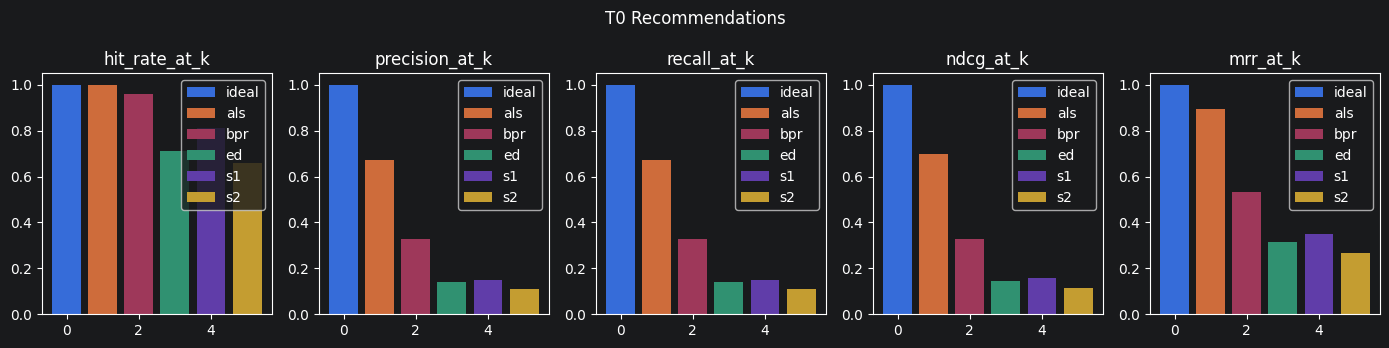

(None, None)

In [12]:
evaluations = [ideal_evaluation, als_evaluation, bpr_evaluation, ed_evaluation, s1_evaluation, s2_evaluation]
_, axs = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, key in zip(axs.ravel(), ['hit_rate_at_k', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'mrr_at_k']):
    for x, evaluation in enumerate(evaluations):
        ax.set_title(key)
        ax.bar(x, evaluation['train'][key])
        ax.legend(['ideal', 'als', 'bpr', 'ed', 's1', 's2'])
plt.suptitle('T0 Recommendations')
plt.tight_layout(), plt.show()

In [25]:
results = [ideal_results, als_results, bpr_results, ed_results, s1_results, s2_results]
aggregate = []
for _ in range(len(results)): aggregate.append({'hit_rate_at_k': 0, 'precision_at_k': 0, 'recall_at_k': 0, 'ndcg_at_k': 0, 'mrr_at_k': 0})

for i, rs in enumerate(results):
    for m in ['hit_rate_at_k', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'mrr_at_k']:
        aggregate[i][m] = np.mean([r[m][-1] for r in rs])

In [26]:
aggregate[0]

{'hit_rate_at_k': np.float64(0.5),
 'precision_at_k': np.float64(0.07500000000000001),
 'recall_at_k': np.float64(0.07500000000000001),
 'ndcg_at_k': np.float64(0.056790543704812006),
 'mrr_at_k': np.float64(0.09166666666666667)}

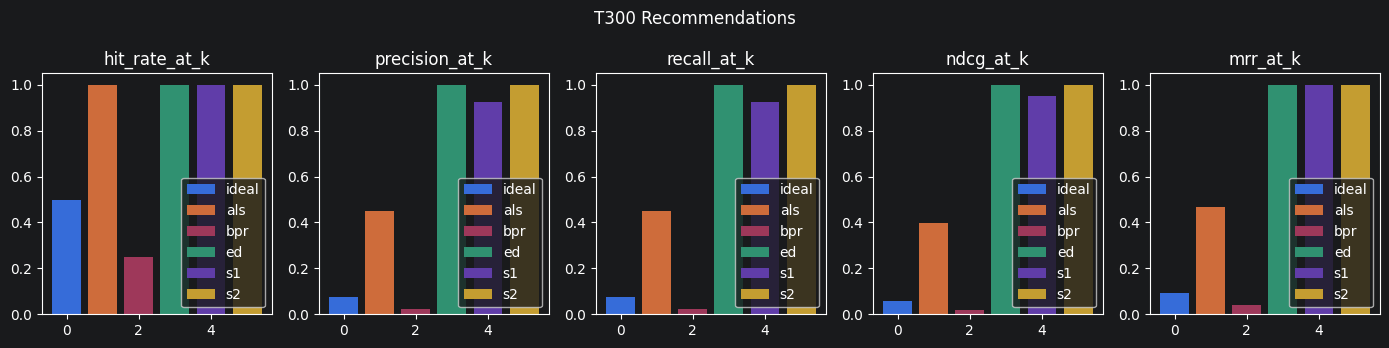

(None, None)

In [30]:
_, axs = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, key in zip(axs.ravel(), ['hit_rate_at_k', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'mrr_at_k']):
    for x, result in enumerate(aggregate):
        ax.set_title(key)
        ax.bar(x, result[key])
        ax.legend(['ideal', 'als', 'bpr', 'ed', 's1', 's2'], loc='lower right')
plt.suptitle('T300 Recommendations')
plt.tight_layout(), plt.show()